# One row per game, and how big home advantage is

`nba_predictor.games` turns the API's two team rows into one game row. Home and away come from the `MATCHUP` text. Each game has to have exactly two rows, agree on who is home, share a date, and have one win and one loss with the winner scoring more.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("NBA_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import pandas as pd

from nba_predictor.evaluate import wilson

data = Path(os.environ["NBA_DATA_DIR"]) / "processed"
report = json.loads((data / "report.json").read_text())
games = pd.read_parquet(data / "games.parquet")
games["margin"] = games["home_pts"] - games["away_pts"]
pd.DataFrame(report["seasons"]).T[["games", "neutral_site", "bubble", "home_win_rate"]]

,games,neutral_site,bubble,home_win_rate
2014-15,1230,0,0,0.5748
2015-16,1230,0,0,0.5886
2016-17,1230,0,0,0.5837
2017-18,1230,0,0,0.5789
2018-19,1230,0,0,0.5927
2019-20,1059,0,88,0.5515
2020-21,1080,0,0,0.5435
2021-22,1230,0,0,0.5439
2022-23,1230,0,0,0.5805
2023-24,1230,0,0,0.5431


- **13,209 games, none dropped.** 1,230 a season except 2019-20 (1,059: the season stopped in March 2020 and only 22 teams went to the bubble) and 2020-21 (1,080: 72 games each).
- **First version dropped 5 games.** In 2024-25, the two Paris games, Mexico City and the two NBA Cup semifinals in Las Vegas write *both* teams' rows as "away @ home". The parser now reads the designated home team from the text and flags these games `neutral`.
- **88 bubble games** (30 July 2020 onwards: no crowds, no travel) are flagged by date.

## Home win rate by season

In [2]:
rows = []
for season, g in games.groupby("season"):
    low, high = wilson(int(g["home_win"].sum()), len(g))
    rows.append(
        {
            "season": season,
            "games": len(g),
            "home_win": g["home_win"].mean(),
            "low": low,
            "high": high,
            "margin": g["margin"].mean(),
        }
    )
by_season = pd.DataFrame(rows).set_index("season")
by_season.round(3)

,games,home_win,low,high,margin
season,,,,,
2014-15,1230,0.575,0.547,0.602,2.407
2015-16,1230,0.589,0.561,0.616,2.675
2016-17,1230,0.584,0.556,0.611,3.149
2017-18,1230,0.579,0.551,0.606,2.106
2018-19,1230,0.593,0.565,0.620,2.724
2019-20,1059,0.551,0.521,0.581,2.130
2020-21,1080,0.544,0.514,0.573,0.944
2021-22,1230,0.544,0.516,0.572,1.723
2022-23,1230,0.580,0.553,0.608,2.500


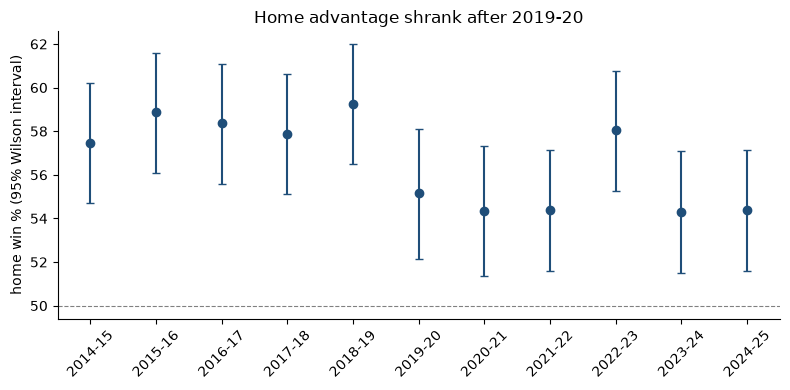

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(by_season))
ax.errorbar(
    x,
    by_season["home_win"] * 100,
    yerr=[
        (by_season["home_win"] - by_season["low"]) * 100,
        (by_season["high"] - by_season["home_win"]) * 100,
    ],
    fmt="o",
    color="#1f4e79",
    capsize=3,
)
ax.axhline(50, color="grey", lw=0.8, ls="--")
ax.set_xticks(list(x), by_season.index, rotation=45)
ax.set_ylabel("home win % (95% Wilson interval)")
ax.set_title("Home advantage shrank after 2019-20")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/home_win_by_season.png", dpi=150)

In [4]:
def summary(name, g):
    low, high = wilson(int(g["home_win"].sum()), len(g))
    return {
        "period": name,
        "games": len(g),
        "home_win": round(g["home_win"].mean(), 3),
        "95%": f"{low:.3f} to {high:.3f}",
        "margin": round(g["margin"].mean(), 2),
    }


pd.DataFrame(
    [
        summary("2014-15 to 2018-19", games[games["season"] <= "2018-19"]),
        summary(
            "2019-20 before the bubble", games[(games["season"] == "2019-20") & ~games["bubble"]]
        ),
        summary("bubble", games[games["bubble"]]),
        summary("2020-21 to 2024-25", games[games["season"] >= "2020-21"]),
        summary("neutral site", games[games["neutral"]]),
    ]
)

,period,games,home_win,95%,margin
0,2014-15 to 2018-19,6150,0.584,0.571 to 0.596,2.61
1,2019-20 before the bubble,971,0.551,0.520 to 0.582,2.17
2,bubble,88,0.557,0.453 to 0.656,1.65
3,2020-21 to 2024-25,6000,0.551,0.539 to 0.564,1.81
4,neutral site,5,0.400,0.118 to 0.769,-13.00


## Findings

1. **Home advantage dropped by about 3 points.** Home teams won 58.4% (57.1 to 59.6) from 2014-15 to 2018-19 and 55.1% (53.9 to 56.4) from 2020-21 on, and the average home margin fell from +2.6 to +1.8 points. The intervals don't overlap. 2022-23 (58.0%) is the one season back at the old level. The drop started before COVID: 2019-20 before the bubble was already at 55.1%, so it isn't only about crowds.
2. **The bubble can't answer the crowd question.** Designated home teams won 55.7% of the 88 bubble games, but with so few games the interval runs from 45% to 66%, which covers both "no advantage" and "the usual advantage". 2020-21, with empty or limited arenas for most of it, had the smallest margin of any season (+0.9).
3. **5 neutral-site games are too few to say anything** and are kept, flagged.

**What this means for the model:** the training seasons (2014-15 to 2019-20) have the strongest home advantage, while validation (2020-21, 2021-22) has the weakest, at 54.4% both years. A model fitted on training will overrate home teams, so day 6 has to check calibration on validation and may need to refit the home term there. That includes Elo's home bonus, which is tuned on validation anyway.